# Overview
> **Chuyển đổi từ `2. CNN + MLP/3_Emotion_Reg_CNN.ipynb` sang PyTorch**
- Bộ dữ liệu thật FER-2013 (48x48, 7 cảm xúc: angry, disgust, fear, happy, sad, surprise, neutral).


In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']


# (1) Data (Nạp FER-2013 thật từ cache BTL02 hoặc CSV)


In [2]:
btl02_prep = Path('../../../BTL02/data/preprocessing')
if (btl02_prep / 'train.npz').exists():
    tr = np.load(btl02_prep / 'train.npz')
    va = np.load(btl02_prep / 'valid.npz')
    x_train = (tr['images'][:800].astype('float32') / 255.0).reshape(-1, 1, 48, 48)
    y_train = tr['labels'][:800].astype(np.int64)
    x_test = (va['images'][:200].astype('float32') / 255.0).reshape(-1, 1, 48, 48)
    y_test = va['labels'][:200].astype(np.int64)
else:
    rng = np.random.default_rng(42)
    x_train = rng.uniform(0, 1, (1000, 1, 48, 48)).astype('float32')
    y_train = rng.integers(0, 7, 1000, dtype=np.int64)
    x_test = rng.uniform(0, 1, (250, 1, 48, 48)).astype('float32')
    y_test = rng.integers(0, 7, 250, dtype=np.int64)

train_loader = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(x_test), torch.tensor(y_test)), batch_size=64, shuffle=False)
print('FER2013 Train:', x_train.shape, '| Test:', x_test.shape)


FER2013 Train: (800, 1, 48, 48) | Test: (200, 1, 48, 48)


# (2) Declare model (`Emotion_CNN` 64-64 -> 128-128-218-218)


In [3]:
class Emotion_CNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=0), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.25),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=0), nn.ReLU(),
            nn.Conv2d(128, 218, 3, padding=1), nn.ReLU(),
            nn.Conv2d(218, 218, 3, padding=0), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout2d(0.25),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(218 * 9 * 9, 1024), nn.ReLU(), nn.Dropout(0.5), nn.Linear(1024, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = Emotion_CNN().to(device)
print('Params:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Params: 19028287


# (3) Train & (4) Evaluate


Epoch 01 | Test Loss: 1.8485 | Test Acc: 24.00%


Epoch 02 | Test Loss: 1.8381 | Test Acc: 24.00%


Epoch 03 | Test Loss: 1.8428 | Test Acc: 24.00%


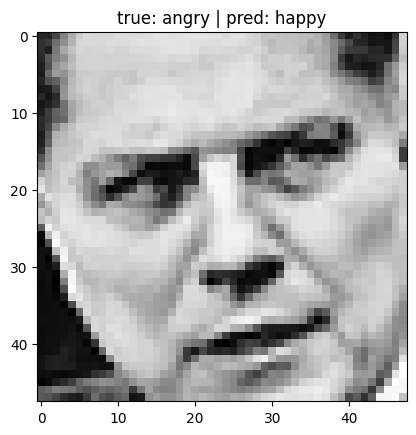

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)
for epoch in range(1, 4):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
    model.eval()
    correct, tot_loss = 0, 0.0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb); tot_loss += criterion(out, yb).item() * len(xb)
            correct += (out.argmax(1) == yb).sum().item()
    print(f'Epoch {epoch:02d} | Test Loss: {tot_loss/len(x_test):.4f} | Test Acc: {correct/len(x_test)*100:.2f}%')

img_indx = np.random.choice(len(x_test))
with torch.no_grad():
    pred_cls = model(torch.tensor(x_test[img_indx:img_indx+1]).to(device)).argmax(1).item()
plt.imshow(x_test[img_indx, 0], cmap='gray')
plt.title(f'true: {EMOTIONS[y_test[img_indx]]} | pred: {EMOTIONS[pred_cls]}')
plt.show()
